# EDA de la OBT
Se inspecciona solo entrenamiento tras reservar 20 % estratificado. La procedencia ejecutada aparece debajo; UCI replay no se presenta como consulta Snowflake.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from IPython.display import display, Image
import pandas as pd
from src.datos import DOCS, split
from src.pipeline import make_pipeline, PhysicalFeatures


In [2]:
from src.eda import run
result = run()
display(result)

{'scope': 'train_only',
 'train_rows': 8000,
 'holdout_rows': 2000,
 'positives_train': 271,
 'prevalence_train': 0.033875,
 'source_scope': 'Reconstrucción local del contrato OBT desde UCI oficial; no es exportación Snowflake',
 'feature_target_spearman': {'air_temperature_k': 0.08639466254461013,
  'process_temperature_k': 0.04459694159495342,
  'rotational_speed_rpm': -0.16353538052426117,
  'torque_nm': 0.16783562372210317,
  'tool_wear_min': 0.09518787844667435,
  'temperature_delta_k': -0.10146503892812514,
  'power_w': 0.15319652038547238},
 'findings': [{'finding': 'Desbalance',
   'evidence': '3.39% fallas en train',
   'consequence': 'AP como métrica principal; CV estratificada; accuracy no decide.'},
  {'finding': 'Colas físicas',
   'evidence': [{'feature': 'air_temperature_k',
     'iqr_outliers': 0,
     'abs_z_ge_3': 0,
     'iqr_low': 293.5,
     'iqr_high': 306.29999999999995},
    {'feature': 'process_temperature_k',
     'iqr_outliers': 0,
     'abs_z_ge_3': 0,
     

In [3]:
display(pd.read_csv(DOCS/'tipos_faltantes.csv'))
display(pd.read_csv(DOCS/'descriptivos.csv'))

,Unnamed: 0,dtype,missing
0,reading_id,int64,0
1,product_type,object,0
2,air_temperature_k,float64,0
3,process_temperature_k,float64,0
4,rotational_speed_rpm,int64,0
5,torque_nm,float64,0
6,tool_wear_min,int64,0
7,machine_failure,int64,0
8,temperature_delta_k,float64,0
9,power_w,float64,0


,Unnamed: 0,product_type,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,temperature_delta_k,power_w,machine_failure
0,count,8000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
1,unique,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,top,L,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,freq,4830,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mean,NaN,300.005450,310.006062,1539.356875,40.003363,107.685000,10.000613,6282.617947,0.033875
5,std,NaN,1.996844,1.479432,180.982943,10.019546,63.612002,0.999854,1072.418510,0.180919
6,min,NaN,295.300000,305.700000,1168.000000,3.800000,0.000000,7.600000,1148.440610,0.000000
7,25%,NaN,298.300000,308.800000,1422.000000,33.200000,53.000000,9.300000,5559.605833,0.000000
8,50%,NaN,300.100000,310.100000,1503.000000,40.100000,107.000000,9.800000,6272.294453,0.000000
9,75%,NaN,301.500000,311.100000,1613.000000,46.800000,163.000000,11.000000,7013.867399,0.000000


,feature,iqr_outliers,abs_z_ge_3,iqr_low,iqr_high
0,air_temperature_k,0,0,293.500000,306.300000
1,process_temperature_k,0,0,305.350000,314.550000
2,rotational_speed_rpm,331,138,1135.500000,1899.500000
3,torque_nm,56,19,12.800000,67.200000
4,tool_wear_min,0,0,-112.000000,328.000000
5,temperature_delta_k,0,0,6.750000,13.550000
6,power_w,50,24,3378.213485,9195.259746


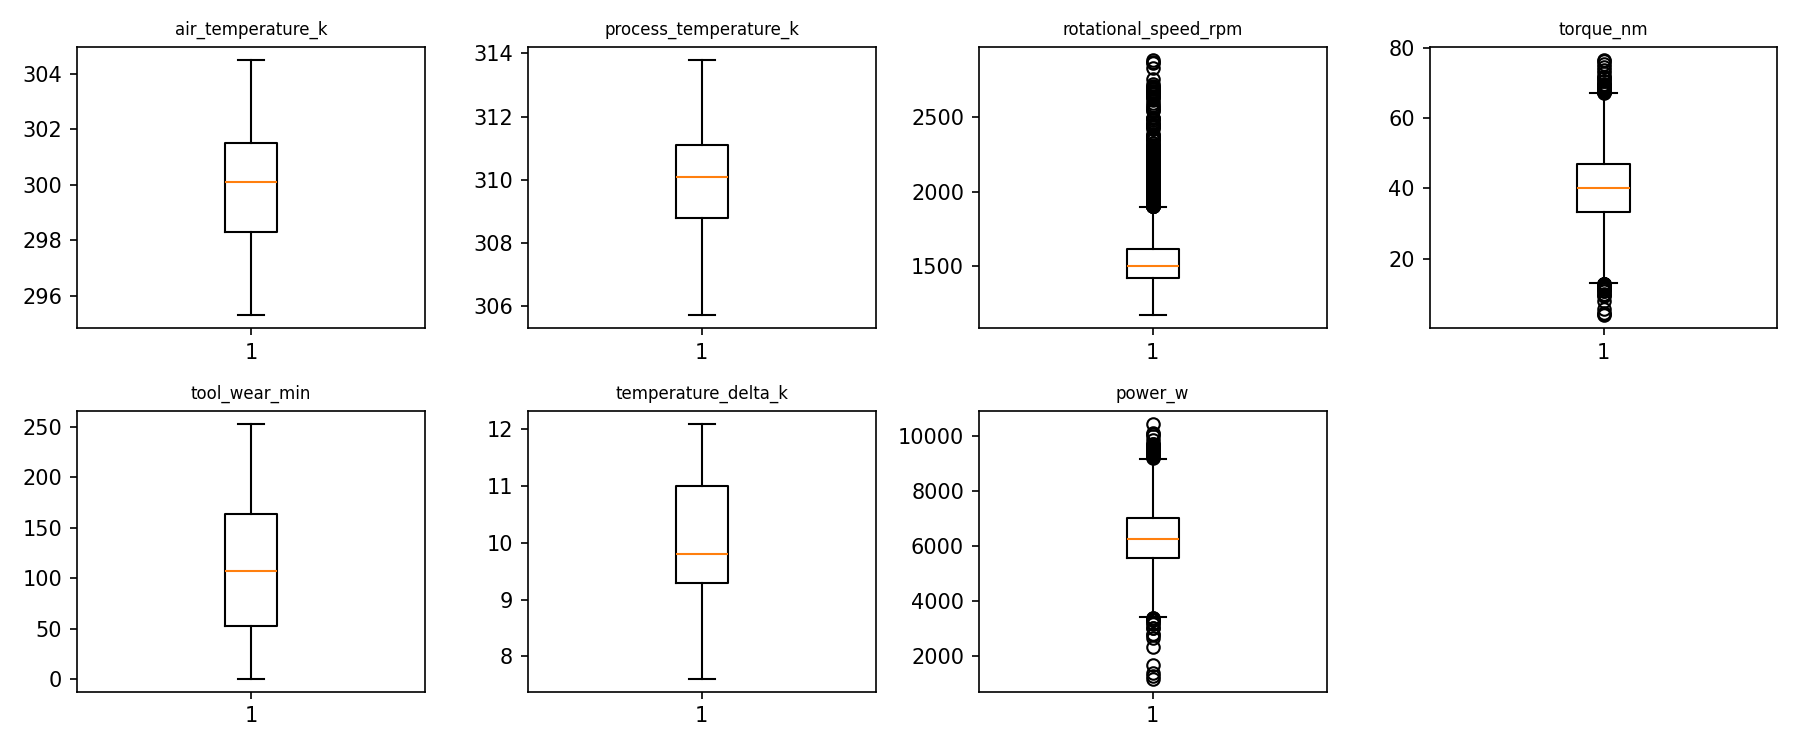

In [4]:
display(pd.read_csv(DOCS/'atipicos.csv'))
display(Image(filename=str(DOCS/'figuras/boxplots.png')))

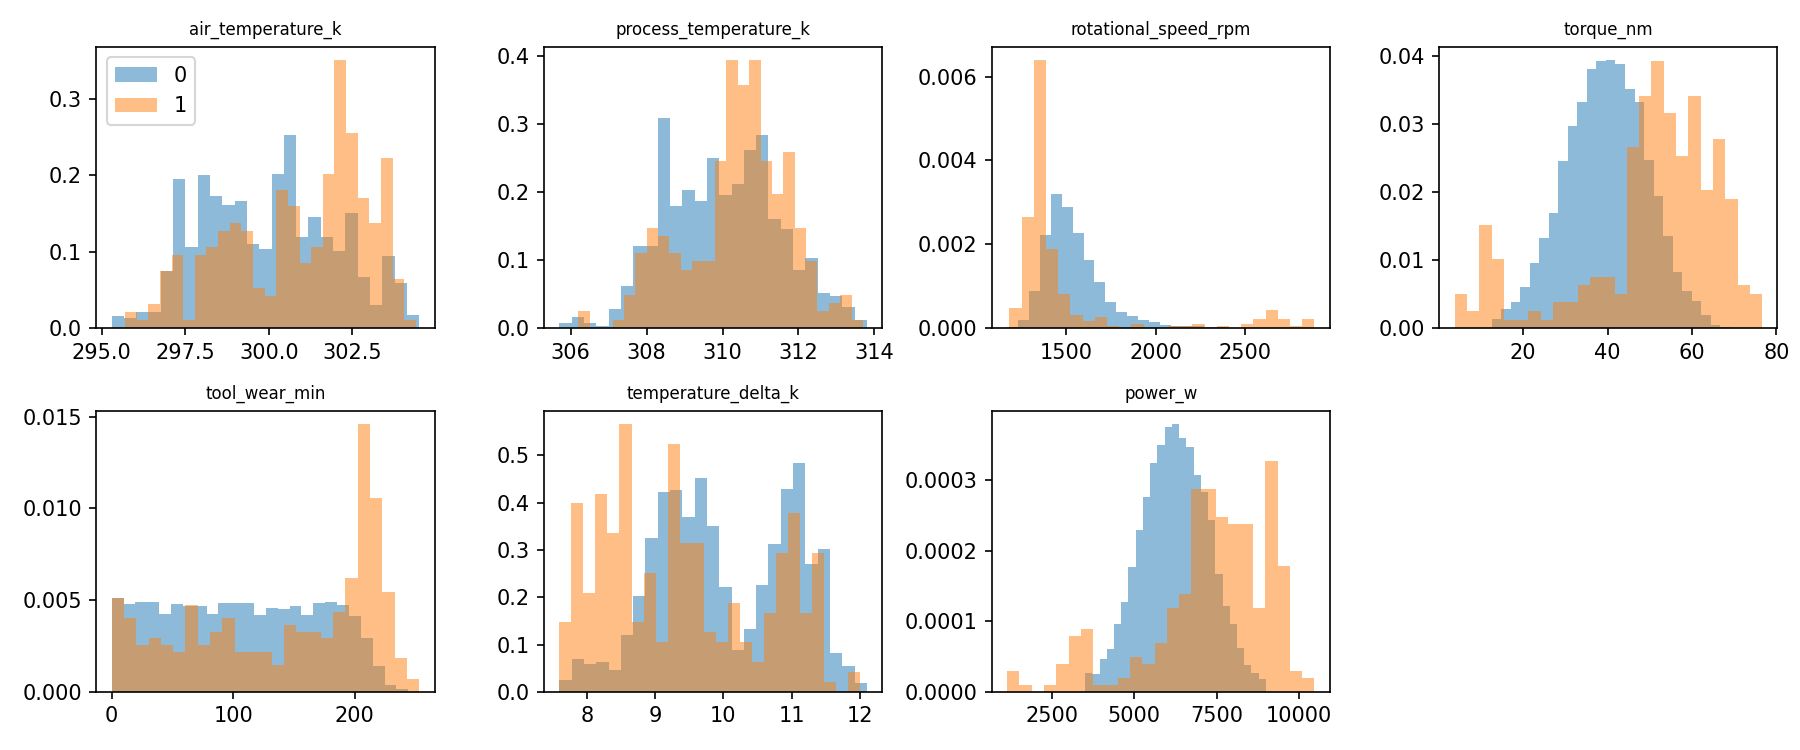

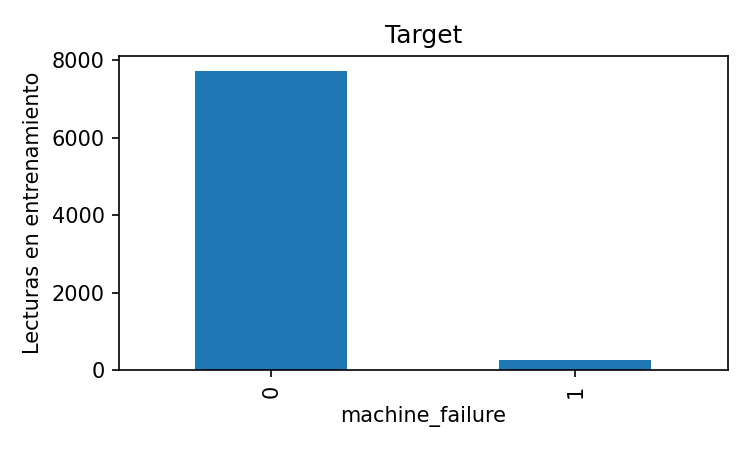

In [5]:
display(Image(filename=str(DOCS/'figuras/distribuciones.png')))
display(Image(filename=str(DOCS/'figuras/target.png')))

,Unnamed: 0,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,temperature_delta_k,power_w,machine_failure
0,air_temperature_k,1.000000,0.864331,0.012930,-0.011769,0.009680,-0.706752,-0.010940,0.086395
1,process_temperature_k,0.864331,1.000000,0.012116,-0.010977,0.012656,-0.269924,-0.009515,0.044597
2,rotational_speed_rpm,0.012930,0.012116,1.000000,-0.916838,0.010113,-0.009768,-0.818119,-0.163535
3,torque_nm,-0.011769,-0.010977,-0.916838,1.000000,-0.010590,0.008067,0.977954,0.167836
4,tool_wear_min,0.009680,0.012656,0.010113,-0.010590,1.000000,-0.000310,-0.009530,0.095188
5,temperature_delta_k,-0.706752,-0.269924,-0.009768,0.008067,-0.000310,1.000000,0.007798,-0.101465
6,power_w,-0.010940,-0.009515,-0.818119,0.977954,-0.009530,0.007798,1.000000,0.153197
7,machine_failure,0.086395,0.044597,-0.163535,0.167836,0.095188,-0.101465,0.153197,1.000000


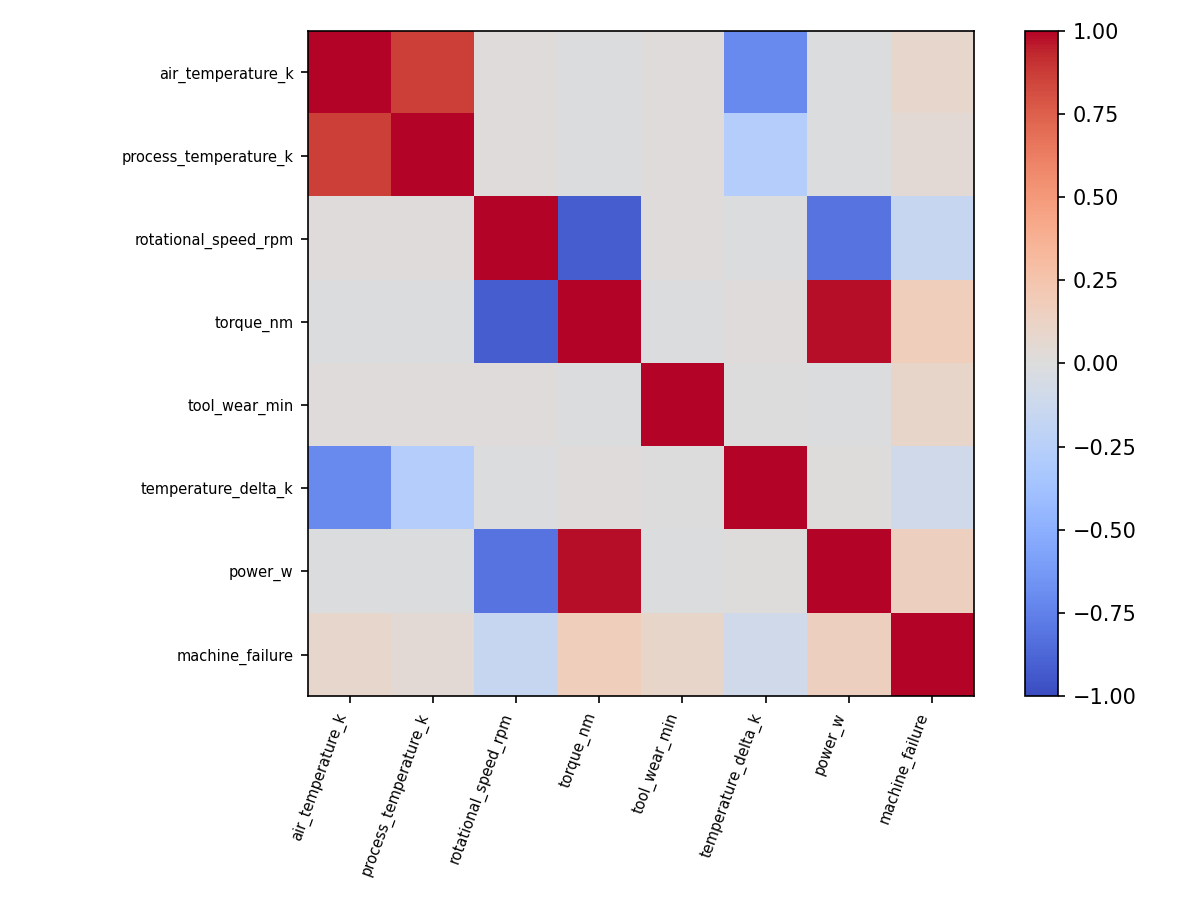

In [6]:
display(pd.read_csv(DOCS/'spearman.csv'))
display(Image(filename=str(DOCS/'figuras/correlacion.png')))

Spearman se usa por colas e interés en relaciones monótonas sin imponer normalidad. Correlación con target binario es descriptiva, no causal. Los atípicos se conservan, pues pueden representar fallas. El desbalance orienta AP y CV estratificada; no se sobremuestrea antes de dividir. Tres hallazgos con consecuencia están en eda.json.